In [1]:
import sys
from pathlib import Path
import pandas as pd

src_path = r"D:\TimeSeries_Data\total_practice\Practice_2\src"

if src_path not in sys.path:
    sys.path.insert(0, src_path)

PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent] if (p / 'datasets' / 'raw' / 'a10.csv').is_file()), None)
if PROJECT_ROOT is None: raise FileNotFoundError('Không tìm thấy Practice 2 root')
RAW_PATH = PROJECT_ROOT / 'datasets' / 'raw' / 'airline-passengers.csv'

### Đọc dữ liệu

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Đọc file dữ liệu
df = pd.read_csv(RAW_PATH)

# Chuyển Month sang datetime và đặt làm index
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").set_index("Month")

# Tạo chuỗi thời gian
series = df["Passengers"].astype(float).asfreq("MS")

# Kiểm tra dữ liệu
print(series.head())
print("Số quan sát:", len(series))
print("Giá trị thiếu:", series.isna().sum())
print("Thời gian:", series.index.min(), "đến", series.index.max())

Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64
Số quan sát: 144
Giá trị thiếu: 0
Thời gian: 1949-01-01 00:00:00 đến 1960-12-01 00:00:00


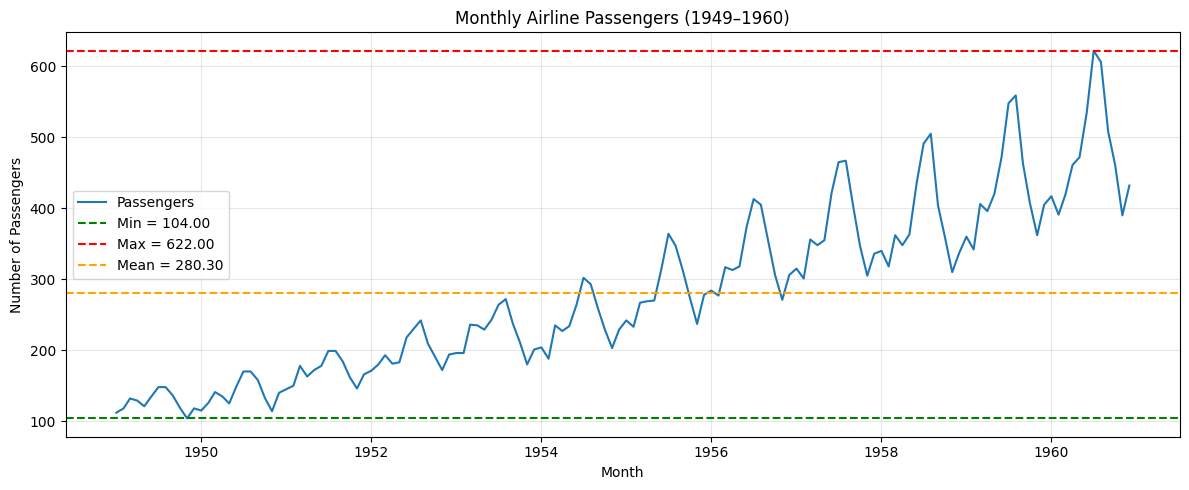

In [3]:
plt.figure(figsize=(12, 5))
# Vẽ chuỗi thời gian
plt.plot(series.index, series.values, label="Passengers")
# Tính các giá trị thống kê
min_value = series.min()
max_value = series.max()
mean_value = series.mean()
# Vẽ các đường ngang
plt.axhline(min_value, color="green", linestyle="--",
            label=f"Min = {min_value:.2f}")
plt.axhline(max_value, color="red", linestyle="--",
            label=f"Max = {max_value:.2f}")
plt.axhline(mean_value, color="orange", linestyle="--",
            label=f"Mean = {mean_value:.2f}")
plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Chia train/test

In [4]:
n_train = int(len(series) * 0.8)

train_series = series.iloc[:n_train]
test_series = series.iloc[n_train:]

print("Train:", len(train_series))
print("Test:", len(test_series))
print("Train kết thúc:", train_series.index.max())
print("Test bắt đầu:", test_series.index.min())


Train: 115
Test: 29
Train kết thúc: 1958-07-01 00:00:00
Test bắt đầu: 1958-08-01 00:00:00


### Kiểm định ADF trên chuỗi gốc

In [5]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(series.dropna(), autolag="AIC")

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4]['5%'])

if adf_result[1] < 0.05:
    print("Bác bỏ H0: Có bằng chứng chuỗi dừng.")
else:
    print("Chưa đủ bằng chứng bác bỏ H0: Chuỗi có thể không dừng.")


ADF Statistic: 0.8153688792060482
p-value: 0.991880243437641
Critical Values: -2.8840418343195267
Chưa đủ bằng chứng bác bỏ H0: Chuỗi có thể không dừng.


C:\Users\PC\AppData\Local\Temp\ipykernel_15884\2284123459.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series.dropna(), autolag="AIC")


### Sai phân thường và sai phân mùa vụ

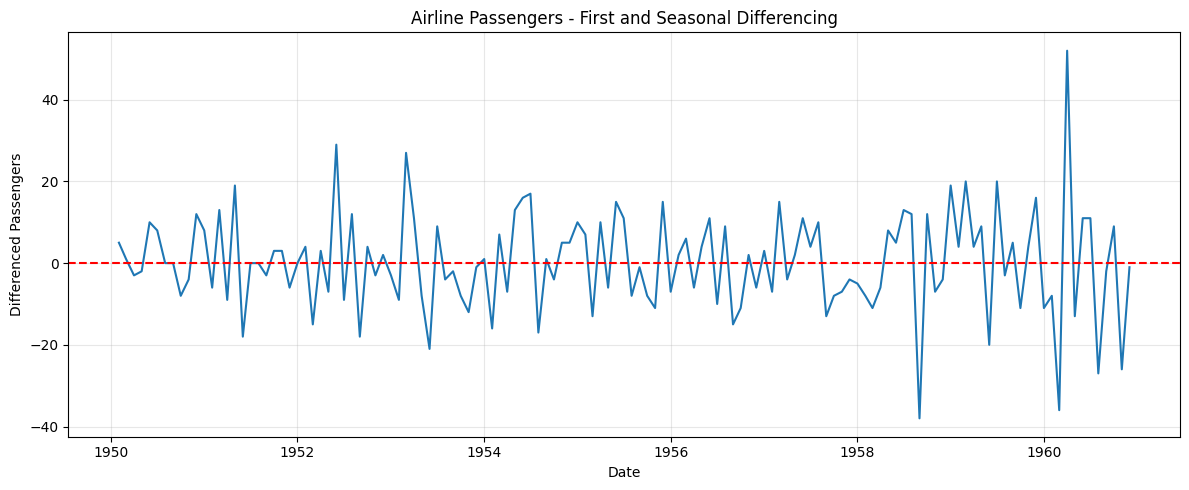

In [9]:
# Sai phân thường + mùa vụ 
series_combined_diff = series.diff().diff(12).dropna()

# Vẽ chuỗi sau sai phân kết hợp
plt.figure(figsize=(12, 5))
plt.plot(
    series_combined_diff.index,
    series_combined_diff.values
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Airline Passengers - First and Seasonal Differencing")
plt.xlabel("Date")
plt.ylabel("Differenced Passengers")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Kiểm định ADF lần nữa trên chuỗi sai phân

In [7]:
adf_diff = adfuller(series_combined_diff, autolag="AIC")

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])
print("Critical Values:", adf_diff[4]['5%'])

if adf_diff[1] < 0.05:
    print("Bác bỏ H0: Chuỗi sai phân kết hợp có bằng chứng dừng.")
else:
    print("Chưa đủ bằng chứng bác bỏ H0: Cần xem xét thêm.")


ADF Statistic: -15.595618083746334
p-value: 1.8565116001234705e-28
Critical Values: -2.8840418343195267
Bác bỏ H0: Chuỗi sai phân kết hợp có bằng chứng dừng.


C:\Users\PC\AppData\Local\Temp\ipykernel_15884\3864169748.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(series_combined_diff, autolag="AIC")


### **Vẽ ACF/PACF**

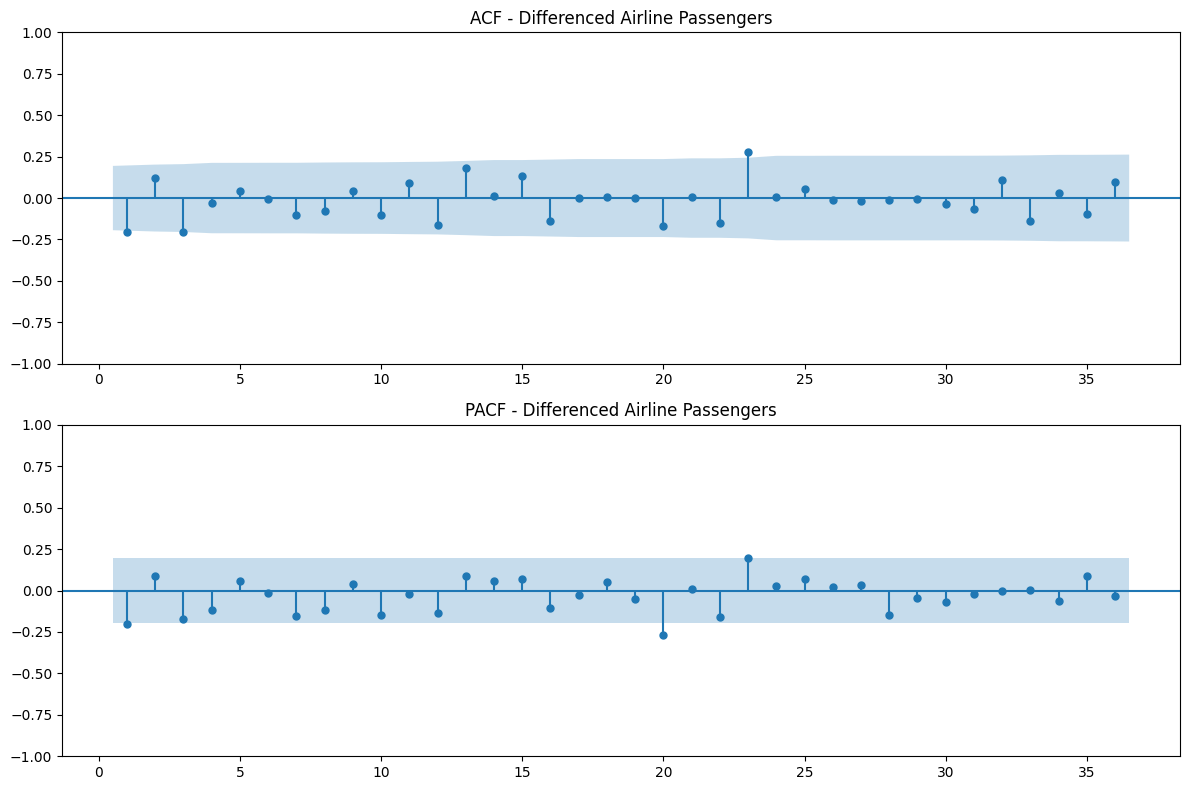

In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

train_diff = train_series.diff().diff(12).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(train_diff, lags=36, zero=False, ax=axes[0])
axes[0].set_title("ACF - Differenced Airline Passengers")

plot_pacf(
    train_diff,
    lags=36,
    zero=False,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF - Differenced Airline Passengers")

plt.tight_layout()
plt.show()


Vì đẫ thực hiện sai phân thường bậc 1 và sai phân mùa vụ bậc 1 với chu kỳ 12, do đó cấu hình sai phân đã được xác định như sau: d = 1, D = 1, s =12

Kết quả cho thấy ACF có một số lag đáng chú ý như lag 1, lag 3 và lag 24; PACF có dấu hiệu tương quan tại lag 1 và lag 20. 

Vì vậy, nhóm đề xuất thử nghiệm hai mô hình SARIMA(0,1,1)(0,1,1,12) và SARIMA(1,1,1)(0,1,1,12), sau đó lựa chọn mô hình phù hợp thông qua AIC, BIC và sai số dự báo MAE, RMSE.

### **Fit SARIMA**

In [13]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd

# Khởi tạo danh sách lưu kết quả
sarima_results = {}

In [14]:
# Khởi tạo mô hình
sarima_1 = SARIMAX(
    train_series,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Huấn luyện mô hình
sarima_result_1 = sarima_1.fit(disp=False)

# Lưu kết quả
sarima_results["SARIMA(0,1,1)(0,1,1,12)"] = sarima_result_1

# Hiển thị kết quả
print(sarima_result_1.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -326.671
Date:                            Wed, 04 Nov 2026   AIC                            659.342
Time:                                    01:43:00   BIC                            666.774
Sample:                                01-01-1949   HQIC                           662.336
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1672      0.101     -1.659      0.097      -0.365       0.030
ma.S.L12      -0.1283      0.098   

In [15]:
# Khởi tạo mô hình
sarima_2 = SARIMAX(
    train_series,
    order=(1, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Huấn luyện mô hình
sarima_result_2 = sarima_2.fit(disp=False)

# Lưu kết quả
sarima_results["SARIMA(1,1,1)(0,1,1,12)"] = sarima_result_2

# Hiển thị kết quả
print(sarima_result_2.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -325.666
Date:                            Wed, 04 Nov 2026   AIC                            659.333
Time:                                    01:43:21   BIC                            669.242
Sample:                                01-01-1949   HQIC                           663.325
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6512      0.339     -1.920      0.055      -1.316       0.014
ma.L1          0.4706      0.381   

In [16]:
sarima_comparison = pd.DataFrame({
    "Model": list(sarima_results.keys()),
    "AIC": [result.aic for result in sarima_results.values()],
    "BIC": [result.bic for result in sarima_results.values()]
})

display(sarima_comparison)

,Model,AIC,BIC
0,"SARIMA(0,1,1)(0,1,1,12)",659.341569,666.773579
1,"SARIMA(1,1,1)(0,1,1,12)",659.332685,669.242032


### **Forecast – Dự báo trên tập Test**

**Biểu đồ Forecast SARIMA(0,1,1)(0,1,1,12)**

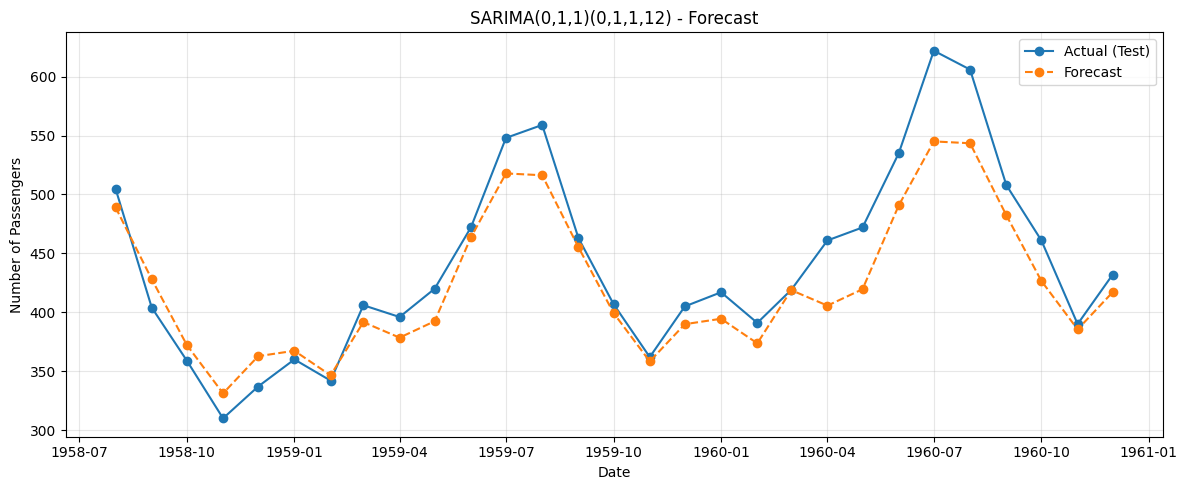

In [22]:
forecast_1 = sarima_result_1.forecast(steps=len(test_series))
plt.figure(figsize=(12, 5))

# Dữ liệu thực tế trên tập Test
plt.plot(
    test_series.index,
    test_series.values,
    label="Actual (Test)",
    marker="o"
)

# Giá trị dự báo
plt.plot(
    forecast_1.index,
    forecast_1.values,
    label="Forecast",
    linestyle="--",
    marker="o"
)

plt.title("SARIMA(0,1,1)(0,1,1,12) - Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Biểu đồ Forecast SARIMA(1,1,1)(0,1,1,12)**

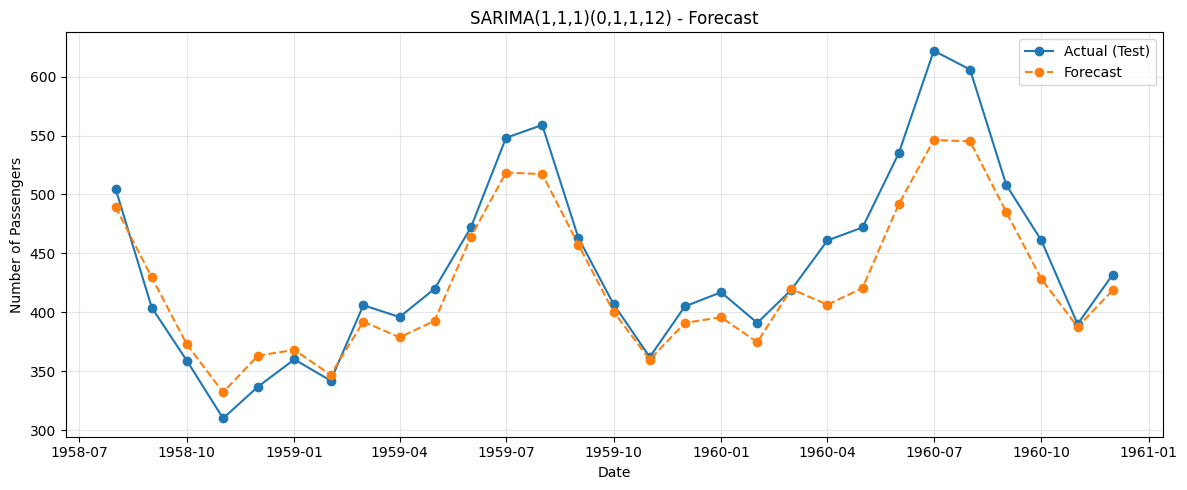

In [23]:
forecast_2 = sarima_result_2.forecast(steps=len(test_series))
plt.figure(figsize=(12, 5))

# Dữ liệu thực tế trên tập Test
plt.plot(
    test_series.index,
    test_series.values,
    label="Actual (Test)",
    marker="o"
)

# Giá trị dự báo
plt.plot(
    forecast_2.index,
    forecast_2.values,
    label="Forecast",
    linestyle="--",
    marker="o"
)

plt.title("SARIMA(1,1,1)(0,1,1,12) - Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **Đánh giá (MAE, RMSE)**

In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Dự báo bằng hai mô hình trên tập Test
forecast_1 = sarima_result_1.forecast(steps=len(test_series))
forecast_2 = sarima_result_2.forecast(steps=len(test_series))

# Tính sai số mô hình 1
mae_1 = mean_absolute_error(test_series, forecast_1)
rmse_1 = np.sqrt(mean_squared_error(test_series, forecast_1))

# Tính sai số mô hình 2
mae_2 = mean_absolute_error(test_series, forecast_2)
rmse_2 = np.sqrt(mean_squared_error(test_series, forecast_2))

# Tổng hợp kết quả
evaluation = pd.DataFrame({
    "Model": [
        "SARIMA(0,1,1)(0,1,1,12)",
        "SARIMA(1,1,1)(0,1,1,12)"
    ],
    "MAE": [mae_1, mae_2],
    "RMSE": [rmse_1, rmse_2]
})

display(evaluation)

,Model,MAE,RMSE
0,"SARIMA(0,1,1)(0,1,1,12)",24.059215,30.580048
1,"SARIMA(1,1,1)(0,1,1,12)",23.367858,29.923085


**Mô hình SARIMA(1,1,1)(0,1,1,12) cho kết quả dự báo tốt hơn với MAE = 23.3679 và RMSE = 29.9231, thấp hơn mô hình SARIMA(0,1,1)(0,1,1,12). Do đó, mô hình SARIMA(1,1,1)(0,1,1,12) được ưu tiên lựa chọn.**